## Pré-processing et Feature Engineering

## Chargement des données

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
import warnings

pd.set_option("display.max_columns", None)

In [2]:
df_2014 = pd.read_csv(
    "../data/co2_2014.csv",
    encoding="latin1",
    sep=";"
)

df_2014.head()

,lib_mrq,lib_mod_doss,lib_mod,dscom,cnit,tvv,cod_cbr,hybride,puiss_admin_98,puiss_max,typ_boite_nb_rapp,conso_urb,conso_exurb,conso_mixte,co2,co_typ_1,hc,nox,hcnox,ptcl,masse_ordma_min,masse_ordma_max,champ_v9,date_maj,Carrosserie,gamme,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29
0,ALFA-ROMEO,159,159,159 1750 Tbi (200ch),M10ALFVP000G340,939AXN1B52C,ES,non,12,147,M 6,"11,30000019","5,800000191","7,800000191",182.0,"0,647000015","0,052000001","0,032000002",NaN,"0,002",1505,1505,715/2007*692/2008EURO5,mars-14,BERLINE,MOY-SUPER,NaN,NaN,NaN,NaN
1,ALFA-ROMEO,159,159,159 1750 Tbi (200ch),M10ALFVP000H341,939BXN1B53C,ES,non,12,147,M 6,"11,5",6,8,186.0,"0,647000015","0,052000001","0,032000002",NaN,"0,002",1555,1555,715/2007*692/2008EURO5,mars-14,BERLINE,MOY-SUPER,NaN,NaN,NaN,NaN
2,ALFA-ROMEO,159,159,159 2.0 JTDm (136ch),M10ALFVP000E302,939AXR1B64,GO,non,7,100,M 6,"6,599999905","4,199999809","5,099999905",134.0,"0,066",NaN,"0,149000004","0,174999997","0,001",1565,1565,715/2007*692/2008EURO5,mars-14,BERLINE,MOY-SUPER,NaN,NaN,NaN,NaN
3,ALFA-ROMEO,159,159,159 2.0 JTDm (136ch),M10ALFVP000F303,939AXR1B64B,GO,non,7,100,M 6,"6,599999905","4,199999809","5,099999905",134.0,"0,066",NaN,"0,149000004","0,174999997","0,001",1565,1565,715/2007*692/2008EURO5,mars-14,BERLINE,MOY-SUPER,NaN,NaN,NaN,NaN
4,ALFA-ROMEO,159,159,159 2.0 JTDm (170ch),M10ALFVP000G304,939AXS1B66,GO,non,9,125,M 6,"6,900000095","4,300000191","5,300000191",139.0,"0,059999999",NaN,"0,164000005","0,193000004","0,001",1565,1565,715/2007*692/2008EURO5,mars-14,BERLINE,MOY-SUPER,NaN,NaN,NaN,NaN



## État initial du dataset

In [3]:

print("Dimensions du dataset :", df_2014.shape)

Dimensions du dataset : (55044, 30)


In [4]:
df_2014.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55044 entries, 0 to 55043
Data columns (total 30 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   lib_mrq            55044 non-null  object 
 1   lib_mod_doss       55044 non-null  object 
 2   lib_mod            55044 non-null  object 
 3   dscom              55044 non-null  object 
 4   cnit               55044 non-null  object 
 5   tvv                55044 non-null  object 
 6   cod_cbr            55044 non-null  object 
 7   hybride            55044 non-null  object 
 8   puiss_admin_98     55044 non-null  int64  
 9   puiss_max          55044 non-null  object 
 10  typ_boite_nb_rapp  55044 non-null  object 
 11  conso_urb          55001 non-null  object 
 12  conso_exurb        55001 non-null  object 
 13  conso_mixte        55010 non-null  object 
 14  co2                55010 non-null  float64
 15  co_typ_1           54886 non-null  object 
 16  hc                 977

Le jeu de données contient 55 044 observations et 30 variables.

Les variables décrivent les caractéristiques techniques des véhicules homologués en France en 2014 : marque, modèle, type de carburant, puissance, consommation, masse, norme environnementale et émissions de CO₂.

Avant toute modélisation, une phase de prétraitement est réalisée afin de nettoyer les données, traiter les valeurs manquantes et préparer le jeu de données pour les étapes suivantes. Conformément aux bonnes pratiques, les transformations apprenant des informations à partir des données (imputation, encodage ou standardisation) seront ajustées uniquement sur le jeu d'entraînement avant d'être appliquées au jeu de test, afin d'éviter tout risque de data leakage.

## VÉRIFICATION DES IDENTIFIANTS VÉHICULE / MODÈLE

In [5]:
# ============================================================
# VÉRIFICATION DES IDENTIFIANTS VÉHICULE / MODÈLE
# ============================================================

# Afficher toutes les colonnes du jeu de données
print("Colonnes disponibles :")
print(df_2014.columns.tolist())

# Rechercher les colonnes pouvant correspondre à un identifiant
colonnes_identifiants = [
    col for col in df_2014.columns
    if any(mot in col.lower() for mot in [
        "id", "ident", "vin", "immat", "numero", "numéro"
    ])
]

print("\nColonnes pouvant correspondre à un identifiant :")
print(colonnes_identifiants)

# Vérifier les colonnes dont toutes les valeurs sont uniques
colonnes_uniques = [
    col for col in df_2014.columns
    if df_2014[col].is_unique
]

print("\nColonnes avec une valeur unique par ligne :")
print(colonnes_uniques)

Colonnes disponibles :
['lib_mrq', 'lib_mod_doss', 'lib_mod', 'dscom', 'cnit', 'tvv', 'cod_cbr', 'hybride', 'puiss_admin_98', 'puiss_max', 'typ_boite_nb_rapp', 'conso_urb', 'conso_exurb', 'conso_mixte', 'co2', 'co_typ_1', 'hc', 'nox', 'hcnox', 'ptcl', 'masse_ordma_min', 'masse_ordma_max', 'champ_v9', 'date_maj', 'Carrosserie', 'gamme', 'Unnamed: 26', 'Unnamed: 27', 'Unnamed: 28', 'Unnamed: 29']

Colonnes pouvant correspondre à un identifiant :
['hybride']

Colonnes avec une valeur unique par ligne :
[]


## Contrôle des doublons

Avant de poursuivre le nettoyage des données, un contrôle des doublons stricts est réalisé.

Un doublon strict correspond à deux observations présentant exactement les mêmes valeurs sur l'ensemble des variables. Ce contrôle est réalisé avant les principales transformations du jeu de données afin d'évaluer la présence de doublons dans les données initiales.

In [6]:
# ============================================================
# CONTRÔLE DES DOUBLONS STRICTS
# ============================================================

nb_lignes = len(df_2014)
nb_doublons = df_2014.duplicated().sum()

print("Nombre total de lignes :", nb_lignes)
print("Nombre de doublons stricts :", nb_doublons)
print(
    "Part des doublons :",
    round(nb_doublons / nb_lignes * 100, 2),
    "%"
)

Nombre total de lignes : 55044
Nombre de doublons stricts : 7
Part des doublons : 0.01 %


In [7]:
# Affichage de toutes les lignes appartenant à un groupe de doublons

doublons = df_2014[
    df_2014.duplicated(keep=False)
].sort_values(
    by=list(df_2014.columns)
)

print("Nombre de lignes appartenant à des groupes de doublons :", len(doublons))

doublons

Nombre de lignes appartenant à des groupes de doublons : 14


,lib_mrq,lib_mod_doss,lib_mod,dscom,cnit,tvv,cod_cbr,hybride,puiss_admin_98,puiss_max,typ_boite_nb_rapp,conso_urb,conso_exurb,conso_mixte,co2,co_typ_1,hc,nox,hcnox,ptcl,masse_ordma_min,masse_ordma_max,champ_v9,date_maj,Carrosserie,gamme,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29
1257,CITROEN,C3,C3,C3 VTI (82ch) BVM5,M10CTRVP0051686,SCHMZ0,ES,non,4,60,M 5,"5,599999905","4,099999905","4,599999905",107.0,"0,718999982","0,050000001","0,008",NaN,NaN,1050,1050,"""715/2007*630/2012EURO5",NaN,BERLINE,INFERIEURE,NaN,NaN,NaN,NaN
1258,CITROEN,C3,C3,C3 VTI (82ch) BVM5,M10CTRVP0051686,SCHMZ0,ES,non,4,60,M 5,"5,599999905","4,099999905","4,599999905",107.0,"0,718999982","0,050000001","0,008",NaN,NaN,1050,1050,"""715/2007*630/2012EURO5",NaN,BERLINE,INFERIEURE,NaN,NaN,NaN,NaN
1458,DACIA,SANDERO,SANDERO,Nouvelle SANDERO Stepway TCe (90ch),M10DACVP000J609,5SDAAC,ES,non,5,66,M 5,"6,699999809","4,599999905","5,400000095",124.0,"0,465000004","0,057","0,013",NaN,NaN,1098,1180,715/2007*630/2012EURO5,mars-14,BERLINE,INFERIEURE,NaN,NaN,NaN,NaN
1459,DACIA,SANDERO,SANDERO,Nouvelle SANDERO Stepway TCe (90ch),M10DACVP000J609,5SDAAC,ES,non,5,66,M 5,"6,699999809","4,599999905","5,400000095",124.0,"0,465000004","0,057","0,013",NaN,NaN,1098,1180,715/2007*630/2012EURO5,mars-14,BERLINE,INFERIEURE,NaN,NaN,NaN,NaN
1460,DACIA,SANDERO,SANDERO,Nouvelle SANDERO TCe (90ch) eco2,M10DACVP000W622,5SDAA5,ES,non,5,66,M 5,"6,400000095","4,300000191",5,116.0,"0,671999991","0,075000003","0,011",NaN,NaN,1037,1150,715/2007*630/2012EURO5,mars-14,BERLINE,INFERIEURE,NaN,NaN,NaN,NaN
1461,DACIA,SANDERO,SANDERO,Nouvelle SANDERO TCe (90ch) eco2,M10DACVP000W622,5SDAA5,ES,non,5,66,M 5,"6,400000095","4,300000191",5,116.0,"0,671999991","0,075000003","0,011",NaN,NaN,1037,1150,715/2007*630/2012EURO5,mars-14,BERLINE,INFERIEURE,NaN,NaN,NaN,NaN
2383,HYUNDAI,IX 35,IX 35,ix35 1.6 GDI (135ch) Blue Drive PACK Evidence ...,M10HMCVP001X448,ELHF5P31M64AZ1,ES,non,8,99,M 6,"7,5","5,800000191","6,400000095",149.0,"0,465000004","0,026000001","0,008",NaN,0,1380,1502,715/2007*195/2013EURO5,dÚc-13,TS TERRAINS/CHEMINS,MOY-SUPER,NaN,NaN,NaN,NaN
2384,HYUNDAI,IX 35,IX 35,ix35 1.6 GDI (135ch) Blue Drive PACK Evidence ...,M10HMCVP001X448,ELHF5P31M64AZ1,ES,non,8,99,M 6,"7,5","5,800000191","6,400000095",149.0,"0,465000004","0,026000001","0,008",NaN,0,1380,1502,715/2007*195/2013EURO5,dÚc-13,TS TERRAINS/CHEMINS,MOY-SUPER,NaN,NaN,NaN,NaN
40309,PEUGEOT,107,107,107 3P 1.0e Blue Lion,M10PGTVP0086492,PMCFB4,ES,non,4,50,M 5,"5,099999905","3,799999952","4,300000191",99.0,"0,419","0,035","0,006",NaN,NaN,875,925,715/2007*630/2012EURO5,mars-14,BERLINE,ECONOMIQUE,NaN,NaN,NaN,NaN
40310,PEUGEOT,107,107,107 3P 1.0e Blue Lion,M10PGTVP0086492,PMCFB4,ES,non,4,50,M 5,"5,099999905","3,799999952","4,300000191",99.0,"0,419","0,035","0,006",NaN,NaN,875,925,715/2007*630/2012EURO5,mars-14,BERLINE,ECONOMIQUE,NaN,NaN,NaN,NaN


### Traitement des doublons

L'analyse met en évidence 7 doublons stricts, correspondant à 14 lignes regroupées en 7 paires identiques.

Pour chacune de ces paires, l'ensemble des variables présente les mêmes valeurs. Ces doublons n'apportent aucune information supplémentaire et risquent de surreprésenter certains véhicules lors des analyses et de la modélisation.

Une seule occurrence de chaque observation est conservée.

In [8]:
# ============================================================
# SUPPRESSION DES DOUBLONS STRICTS
# ============================================================

df_2014 = df_2014.drop_duplicates().copy()

print("Dimensions après suppression des doublons :", df_2014.shape)
print(
    "Nombre de doublons stricts restants :",
    df_2014.duplicated().sum()
)

Dimensions après suppression des doublons : (55037, 30)
Nombre de doublons stricts restants : 0


## Analyse complémentaire des doublons

Après la suppression des 7 doublons stricts, une analyse complémentaire est réalisée afin d'identifier les observations présentant des caractéristiques identiques, à l'exclusion des références techniques cnit et tvv.

Cette comparaison permet de distinguer les doublons stricts des observations partageant les mêmes caractéristiques renseignées mais possédant des références techniques différentes.

Les observations ainsi identifiées sont conservées, car elles présentent des références techniques distinctes et ne peuvent donc pas être considérées comme des doublons stricts.

In [9]:

# ============================================================
# ANALYSE COMPLÉMENTAIRE DES DOUBLONS HORS CNIT ET TVV
# ============================================================

# Comparaison sur toutes les colonnes sauf les références techniques
colonnes_comparaison = [
    col for col in df_2014.columns
    if col not in ["cnit", "tvv"]
]

# Identification des occurrences répétées
nb_occurrences_repetees = df_2014.duplicated(
    subset=colonnes_comparaison
).sum()

# Constitution des groupes d'observations identiques
groupes = df_2014.groupby(
    colonnes_comparaison,
    dropna=False
)

# Identification des groupes contenant plusieurs observations
tailles_groupes = groupes.size()
groupes_repetes = tailles_groupes[tailles_groupes > 1]

# Vérification des références CNIT dans ces groupes
nb_groupes_cnit_distincts = (
    groupes["cnit"]
    .nunique(dropna=False)
    .loc[groupes_repetes.index]
    .gt(1)
    .sum()
)

# Affichage des résultats
print("ANALYSE DES OCCURRENCES RÉPÉTÉES HORS CNIT ET TVV")
print("-" * 55)

print("Nombre d'observations :", len(df_2014))
print("Occurrences répétées :", nb_occurrences_repetees)
print("Groupes de plusieurs observations :", len(groupes_repetes))
print("Groupes avec plusieurs CNIT :", nb_groupes_cnit_distincts)

print("\nAucune observation supprimée.")

ANALYSE DES OCCURRENCES RÉPÉTÉES HORS CNIT ET TVV
-------------------------------------------------------
Nombre d'observations : 55037
Occurrences répétées : 46399
Groupes de plusieurs observations : 4388
Groupes avec plusieurs CNIT : 4388

Aucune observation supprimée.


### Bilan Recherche des doublons et identification des véhicules

Une vérification des doublons a été réalisée sur l'ensemble des
colonnes du jeu de données 2014.

Cette analyse a permis d'identifier 7 doublons stricts, qui ont
été supprimés. Le nombre d'observations est ainsi passé de
55 044 à 55 037.

Une analyse des colonnes a également été effectuée afin de
rechercher un éventuel identifiant unique de véhicule.

Aucune colonne ne présente une valeur unique pour chaque
observation. Le jeu de données contient néanmoins des
informations permettant de caractériser les véhicules,
notamment la marque, le modèle et des références techniques
telles que CNIT et TVV.

Ces informations décrivent des types ou versions de véhicules,
mais ne permettent pas d'identifier individuellement chaque
observation de manière unique.

L'analyse complémentaire, réalisée en excluant cnit et tvv de la comparaison, a identifié 46 399 occurrences répétées au sein de 4 388 groupes. Tous ces groupes comportent plusieurs références cnit distinctes. Ces observations ont été conservées, car elles ne constituent pas des doublons stricts.

## Analyse des valeurs manquantes

In [8]:
(df_2014.isnull().mean() * 100).sort_values(ascending=False)

Unnamed: 27          100.000000
Unnamed: 26          100.000000
Unnamed: 29          100.000000
Unnamed: 28          100.000000
date_maj              94.111234
hc                    82.255574
hcnox                 17.953377
ptcl                   4.854916
nox                    0.287080
co_typ_1               0.287080
champ_v9               0.110835
conso_urb              0.078129
conso_exurb            0.078129
conso_mixte            0.061777
co2                    0.061777
typ_boite_nb_rapp      0.000000
puiss_admin_98         0.000000
hybride                0.000000
cod_cbr                0.000000
dscom                  0.000000
cnit                   0.000000
tvv                    0.000000
lib_mod_doss           0.000000
lib_mrq                0.000000
lib_mod                0.000000
puiss_max              0.000000
masse_ordma_max        0.000000
masse_ordma_min        0.000000
gamme                  0.000000
Carrosserie            0.000000
dtype: float64

L'analyse des valeurs manquantes met en évidence plusieurs variables fortement incomplètes.

Les colonnes `Unnamed: 26` à `Unnamed: 29` sont entièrement vides, tandis que la variable `date_maj` présente plus de 94 % de valeurs manquantes. Parmi les variables environnementales, `hc` affiche plus de 82 % de données manquantes et `hcnox` près de 18 %.

La variable `ptcl` présente environ 4,85 % de valeurs manquantes. La majorité des autres variables sont quasiment complètes, avec moins de 1 % de valeurs manquantes.

Ces résultats permettent d'orienter les choix de prétraitement. Les variables très fortement incomplètes pourront être supprimées lorsqu'elles ne présentent pas d'intérêt pour la modélisation, tandis que les variables partiellement renseignées feront l'objet d'un traitement adapté afin de préserver un maximum d'informations.

## Suppression des colonnes vides et peu exploitables

In [9]:
colonnes_a_supprimer = [
    'Unnamed: 26',
    'Unnamed: 27',
    'Unnamed: 28',
    'Unnamed: 29',
    'date_maj'
]

df_2014 = df_2014.drop(columns=colonnes_a_supprimer)

df_2014.shape

(55037, 25)

Les colonnes `Unnamed: 26` à `Unnamed: 29` ont été supprimées car elles étaient entièrement vides et n'apportaient aucune information exploitable.

La variable `date_maj` a également été retirée du jeu de données. Avec plus de 94 % de valeurs manquantes et sans pouvoir explicatif direct identifié pour la prédiction des émissions de CO₂, son exploitation apparaissait peu pertinente pour la suite du projet.

Le dataset passe ainsi de **30 à 25 variables**, tout en conservant les **55 037 observations restantes après suppression des 7 doublons stricts**.

## Traitement des variables fortement incomplètes

In [10]:
df_2014 = df_2014.drop(columns=['hc', 'hcnox'])

df_2014.shape

(55037, 23)

Les variables `hc` et `hcnox` présentent respectivement plus de 82 % et près de 18 % de valeurs manquantes.

La variable `hc` a été supprimée en raison de son très faible niveau de complétude, rendant son imputation peu pertinente.

La variable `hcnox` a également été retirée afin de simplifier le jeu de données et de privilégier des variables environnementales plus complètes. Ce choix constitue une décision de prétraitement, une imputation restant techniquement envisageable compte tenu de son taux de valeurs manquantes.

La variable `ptcl`, bien qu'incomplète, a été conservée car son taux de valeurs manquantes reste limité (moins de 5 %) et elle présente un intérêt potentiel pour l'analyse des émissions polluantes.

Le dataset passe ainsi de **25 à 23 variables**, tout en conservant les **55 037 observations**.

## Conversion des variables numériques

Certaines variables quantitatives ont été importées sous forme de chaînes de caractères en raison de l'utilisation de la virgule comme séparateur décimal. Elles sont converties au format numérique afin de permettre les calculs statistiques, les traitements de prétraitement et les futures étapes de modélisation.

In [11]:
colonnes_numeriques = [
    'puiss_max',
    'conso_urb',
    'conso_exurb',
    'conso_mixte',
    'co_typ_1',
    'nox',
    'ptcl'
]

for col in colonnes_numeriques:
    df_2014[col] = (
        df_2014[col]
        .astype(str)
        .str.replace(',', '.', regex=False)
    )

    df_2014[col] = pd.to_numeric(df_2014[col], errors='coerce')

In [12]:
df_2014.info()

<class 'pandas.core.frame.DataFrame'>
Index: 55037 entries, 0 to 55043
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   lib_mrq            55037 non-null  object 
 1   lib_mod_doss       55037 non-null  object 
 2   lib_mod            55037 non-null  object 
 3   dscom              55037 non-null  object 
 4   cnit               55037 non-null  object 
 5   tvv                55037 non-null  object 
 6   cod_cbr            55037 non-null  object 
 7   hybride            55037 non-null  object 
 8   puiss_admin_98     55037 non-null  int64  
 9   puiss_max          55037 non-null  float64
 10  typ_boite_nb_rapp  55037 non-null  object 
 11  conso_urb          54994 non-null  float64
 12  conso_exurb        54994 non-null  float64
 13  conso_mixte        55003 non-null  float64
 14  co2                55003 non-null  float64
 15  co_typ_1           54879 non-null  float64
 16  nox                54879 no

Les variables concernées ont été converties au format numérique (`float64`), permettant leur utilisation dans les analyses statistiques et les algorithmes de modélisation.

L'utilisation de `pd.to_numeric(errors='coerce')` permet également de transformer les éventuelles valeurs non convertibles en valeurs manquantes (`NaN`).

Ces valeurs seront prises en compte lors des étapes suivantes du prétraitement. Une vérification des valeurs manquantes permettra de contrôler les effets de cette conversion.

In [13]:
# Vérification des valeurs manquantes après conversion numérique

df_2014[colonnes_numeriques].isna().sum()

puiss_max         0
conso_urb        43
conso_exurb      43
conso_mixte      34
co_typ_1        158
nox             158
ptcl           2672
dtype: int64

La vérification réalisée après conversion numérique confirme la présence de valeurs manquantes dans plusieurs variables.

La variable `puiss_max` est entièrement renseignée. Les variables de consommation présentent entre 34 et 43 valeurs manquantes, tandis que `co_typ_1` et `nox` en comptent chacune 158.

La variable `ptcl` reste la plus incomplète parmi les variables numériques converties, avec 2 672 valeurs manquantes.

Ces valeurs seront prises en compte lors des étapes suivantes du prétraitement, selon une stratégie adaptée à chaque variable.

## Choix de la méthode d'imputation

Les variables `ptcl`, `nox` et `co_typ_1` présentent des valeurs manquantes, avec des proportions respectives d'environ 4,85 %, 0,29 % et 0,29 %.

Afin de conserver l'ensemble des observations tout en limitant les biais liés aux données manquantes, plusieurs stratégies d'imputation ont été envisagées.

**1. Imputation par marque de véhicule**

Une première approche consistait à réaliser une imputation par marque de véhicule. Cette solution n'a toutefois pas été retenue en raison de la forte disparité des effectifs entre les marques. Certaines sont représentées par plusieurs dizaines de milliers de véhicules, tandis que d'autres ne comptent que quelques dizaines d'observations, rendant les médianes calculées moins robustes pour les marques les moins représentées.

**2. Imputation par type de carburant**

Une seconde approche repose sur une imputation par type de carburant. Cette stratégie apparaît particulièrement pertinente pour certaines variables environnementales, les émissions polluantes étant liées à la motorisation des véhicules.

Une analyse de la répartition des catégories de carburant, des effectifs associés et des médianes par carburant permettra d'évaluer la pertinence de cette approche.

**3. Imputation par médiane globale**

Enfin, une troisième approche consiste à utiliser la médiane globale du jeu de données. Cette méthode simple et robuste permet de limiter l'influence des valeurs extrêmes sans supprimer d'observations.

Les analyses suivantes permettront de comparer ces stratégies et de justifier le choix de la méthode d'imputation pour chaque variable.

In [14]:
# Répartition des carburants
df_2014['cod_cbr'].value_counts()

cod_cbr
GO       49311
ES        5162
EH         298
GH          81
EL          34
ES/GN       32
GN/ES       32
GP/ES       23
ES/GP       23
GN          21
FE          10
EE           9
GL           1
Name: count, dtype: int64

In [15]:
# Médianes NOx par carburant
df_2014.groupby('cod_cbr')['nox'].median().sort_values()

cod_cbr
EE       0.003
EH       0.006
ES/GP    0.018
FE       0.020
GP/ES    0.026
ES       0.030
GN/ES    0.031
GN       0.032
ES/GN    0.036
GL       0.036
GH       0.061
GO       0.214
EL         NaN
Name: nox, dtype: float64

In [16]:
# Médianes PTCL par carburant
df_2014.groupby('cod_cbr')['ptcl'].median().sort_values()

cod_cbr
GL       0.000
EE       0.001
ES       0.001
EH       0.001
FE       0.001
GH       0.001
GO       0.001
GN       0.007
EL         NaN
ES/GN      NaN
ES/GP      NaN
GN/ES      NaN
GP/ES      NaN
Name: ptcl, dtype: float64

In [17]:
# Médianes CO par carburant
df_2014.groupby('cod_cbr')['co_typ_1'].median().sort_values()

cod_cbr
GL       0.020
GO       0.100
EE       0.132
EH       0.187
GH       0.222
ES       0.238
GN/ES    0.258
ES/GN    0.305
ES/GP    0.360
GN       0.370
GP/ES    0.382
FE       0.632
EL         NaN
Name: co_typ_1, dtype: float64

In [18]:
df_2014.groupby('cod_cbr')[['nox', 'co_typ_1']].count()

,nox,co_typ_1
cod_cbr,,
EE,9,9
EH,298,298
EL,0,0
ES,5089,5089
ES/GN,20,20
ES/GP,23,23
FE,10,10
GH,81,81
GL,1,1


## Analyse des résultats

L'analyse des médianes par carburant met en évidence des différences importantes pour les variables `nox` et `co_typ_1`, notamment entre les véhicules diesel (`GO`) et essence (`ES`).

Pour la variable `nox`, la médiane observée pour les véhicules diesel (0,214) est nettement supérieure à celle des véhicules essence (0,030). Une différence notable est également observée pour `co_typ_1`, avec des médianes respectives de 0,100 pour le diesel et 0,238 pour l'essence.

À l'inverse, les médianes de `ptcl` sont identiques (0,001) pour les principales catégories de carburant, notamment `GO` et `ES`. Certaines catégories minoritaires présentent toutefois des valeurs différentes ou des médianes non calculables.

Les catégories majoritaires (`GO` et `ES`) disposent d'effectifs élevés, favorisant la stabilité des médianes calculées. À l'inverse, certaines catégories peu représentées (notamment `GL`, `FE` ou `EE`) doivent être interprétées avec prudence. Enfin, la catégorie électrique (`EL`) ne comporte aucune valeur disponible pour les variables `nox` et `co_typ_1`.

Ces résultats soutiennent le choix d'une **imputation conditionnelle par carburant** pour les variables `nox` et `co_typ_1`, tandis qu'une **imputation par la médiane globale** est privilégiée pour `ptcl`.

Pour les catégories ne disposant d'aucune médiane calculable, une stratégie de repli devra être prévue afin de traiter les éventuelles valeurs manquantes.

Conformément aux bonnes pratiques de prétraitement, les médianes utilisées pour l'imputation seront calculées uniquement sur le jeu d'entraînement, puis appliquées aux jeux d'entraînement et de test, afin d'éviter toute fuite de données (*data leakage*).

## Analyse des modalités rares

In [19]:
df_2014['lib_mrq'].value_counts(normalize=True) * 100

lib_mrq
MERCEDES        65.810273
VOLKSWAGEN      24.839653
FIAT             0.930283
BMW              0.841252
OPEL             0.724967
LEXUS            0.654105
AUDI             0.634119
FORD             0.541454
NISSAN           0.523284
CITROEN          0.397914
ALFA-ROMEO       0.332504
PEUGEOT          0.314334
RENAULT          0.287080
TOYOTA           0.254374
SKODA            0.238022
MINI             0.227120
PORSCHE          0.198049
VOLVO            0.196232
SEAT             0.196232
ASTON MARTIN     0.141723
CHEVROLET        0.138089
JEEP             0.134455
LAND ROVER       0.134455
KIA              0.121736
LANCIA           0.105384
HONDA            0.101750
SMART            0.094482
HYUNDAI          0.090848
MITSUBISHI       0.079946
MAZDA            0.074495
JAGUAR           0.070861
CADILLAC         0.069044
LAMBORGHINI      0.065411
SUZUKI           0.052692
DACIA            0.049058
BENTLEY          0.047241
FERRARI          0.045424
MASERATI         0.043607
SUBA

L'analyse de la variable `lib_mrq` met en évidence une forte concentration des observations sur deux marques, **MERCEDES et VOLKSWAGEN**, qui représentent ensemble environ **90,65 % du jeu de données**.

À l'inverse, de nombreuses marques sont faiblement représentées, certaines comptant moins de 0,5 % des observations.

Compte tenu de l'objectif de ce premier prétraitement, aucun regroupement des modalités rares n'a été réalisé à ce stade. Cette transformation pourra être envisagée ultérieurement, notamment lors de l'encodage des variables catégorielles, si la variable `lib_mrq` est retenue pour la modélisation.

## Création de nouvelles variables

In [20]:
df_2014['rapport_puissance_masse'] = (
    df_2014['puiss_max'] /
    df_2014['masse_ordma_min']
)

In [21]:
df_2014['rapport_puissance_masse'].describe()

count    55037.000000
mean         0.057802
std          0.024931
min          0.010776
25%          0.045746
50%          0.052016
75%          0.059259
max          0.373802
Name: rapport_puissance_masse, dtype: float64

In [22]:
df_2014[['rapport_puissance_masse', 'co2']].corr()

,rapport_puissance_masse,co2
rapport_puissance_masse,1.000000,0.088854
co2,0.088854,1.000000


In [23]:
# Vérification des valeurs infinies
np.isinf(df_2014['rapport_puissance_masse']).sum()

np.int64(0)

## Décision retenue

Le rapport puissance/masse a été créé afin d'évaluer son intérêt potentiel pour la prédiction des émissions de CO₂.

L'analyse descriptive confirme que cette variable est renseignée pour les **55 037 observations**, sans valeur manquante ni valeur infinie.

La corrélation linéaire observée avec les émissions de CO₂ reste très faible (≈ 0,089), ce qui suggère une relation linéaire limitée.

Toutefois, cette faible corrélation ne permet pas d'exclure l'existence de relations non linéaires ni un éventuel apport prédictif.

La variable `rapport_puissance_masse` est donc **conservée à ce stade du prétraitement**. Son intérêt pourra être évalué lors de la modélisation, en comparant les performances des modèles avec et sans cette variable.

In [24]:
# Création du ratio puissance / masse maximale
df_2014["rapport_puissance_masse_max"] = (
    df_2014["puiss_max"] / df_2014["masse_ordma_max"]
)

In [25]:
df_2014["rapport_puissance_masse_max"].describe()

count    55037.000000
mean         0.053289
std          0.026311
min          0.010776
25%          0.040340
50%          0.046154
75%          0.057637
max          0.373802
Name: rapport_puissance_masse_max, dtype: float64

In [26]:
df_2014[["rapport_puissance_masse_max", "co2"]].corr()

,rapport_puissance_masse_max,co2
rapport_puissance_masse_max,1.000000,0.053921
co2,0.053921,1.000000


In [27]:
# Vérification des valeurs infinies
np.isinf(df_2014['rapport_puissance_masse_max']).sum()

np.int64(0)

### Analyse du rapport puissance/masse maximale

Un second rapport puissance/masse, calculé à partir de la masse maximale du véhicule (`puiss_max / masse_ordma_max`), a également été évalué.

L'analyse descriptive confirme que cette variable est renseignée pour les **55 037 observations**, sans valeur manquante ni valeur infinie.

La corrélation linéaire observée avec les émissions de CO₂ est très faible (≈ 0,054), et inférieure à celle obtenue avec le rapport utilisant la masse minimale (≈ 0,089).

Toutefois, cette faible corrélation ne permet pas d'exclure l'existence de relations non linéaires ni un éventuel apport prédictif.

La variable `rapport_puissance_masse_max` est donc **conservée à ce stade du prétraitement**. Son intérêt pourra être évalué lors de la modélisation, en comparant les performances des modèles avec et sans cette variable.

## Détection des valeurs aberrantes

### Approche graphique

Les valeurs aberrantes (outliers) correspondent à des observations dont les valeurs s'écartent fortement du reste de la distribution.

Leur identification est importante car elles peuvent influencer les analyses statistiques et les performances des modèles de machine learning. Dans le cas présent, l'objectif est d'identifier les éventuelles valeurs extrêmes présentes dans les principales variables quantitatives du dataset afin d'évaluer leur pertinence métier avant toute décision de traitement.

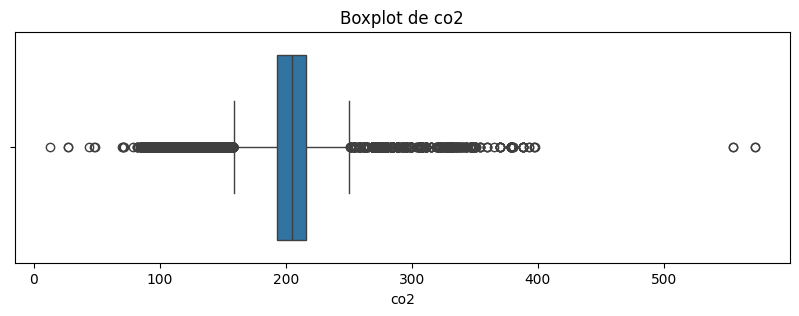

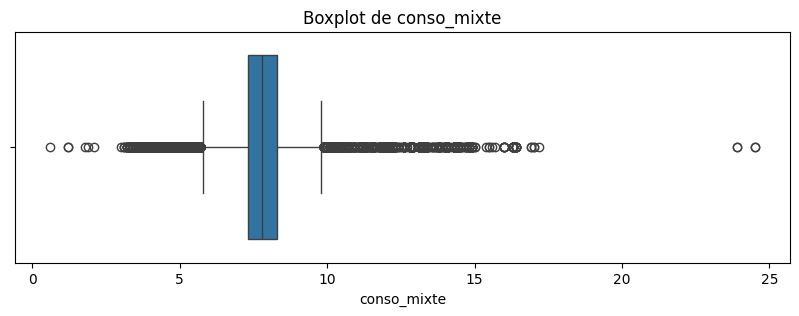

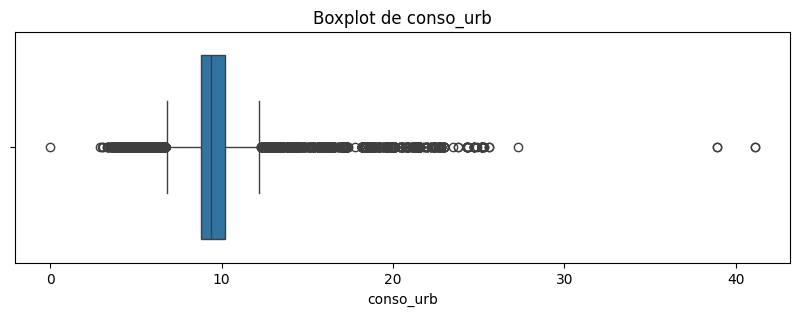

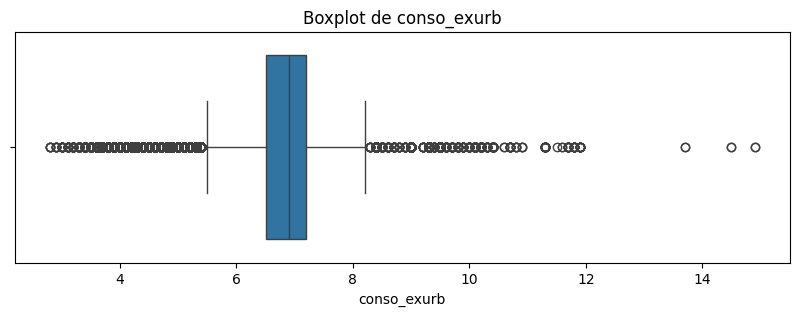

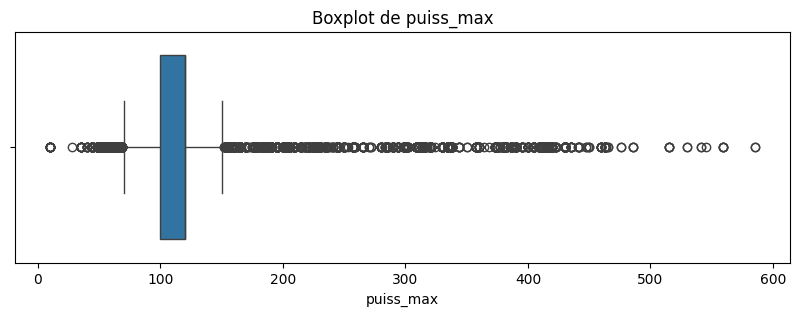

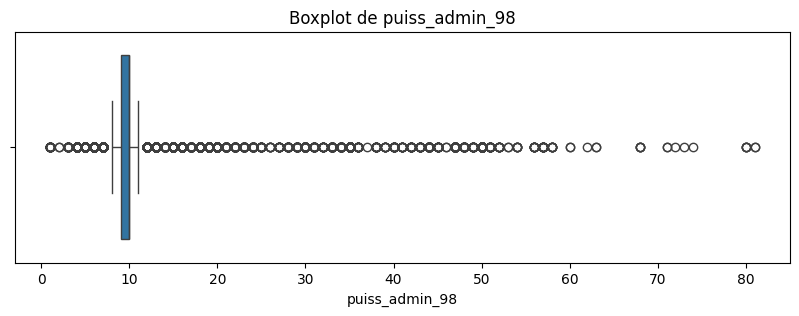

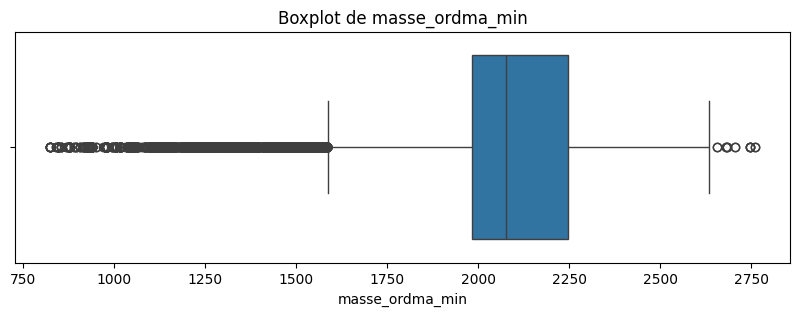

In [28]:
# Variables quantitatives à analyser
colonnes_boxplots = [
    'co2',
    'conso_mixte',
    'conso_urb',
    'conso_exurb',
    'puiss_max',
    'puiss_admin_98',
    'masse_ordma_min'
]

# Visualisation des valeurs aberrantes
for col in colonnes_boxplots:
    plt.figure(figsize=(10, 3))
    sns.boxplot(x=df_2014[col])
    plt.title(f"Boxplot de {col}")
    plt.show()

### Approche statistique (méthode de l'IQR)

Afin de compléter l'analyse graphique réalisée à l'aide des boxplots, une détection statistique des valeurs aberrantes est effectuée à l'aide de la méthode de l'intervalle interquartile (IQR).

Cette méthode repose sur le calcul des premier (Q1) et troisième (Q3) quartiles de chaque variable. Les observations situées en dehors des bornes définies par **Q1 − 1,5 × IQR** et **Q3 + 1,5 × IQR**, où **IQR = Q3 − Q1**, sont considérées comme des valeurs aberrantes.

L'objectif est de confirmer, de manière quantitative, la présence de valeurs extrêmes observées lors de l'analyse graphique et d'évaluer leur importance dans les principales variables numériques du jeu de données.

In [29]:
# ============================================================
# DÉTECTION STATISTIQUE DES VALEURS ABERRANTES - MÉTHODE IQR
# ============================================================

resultats_iqr = []

for var in colonnes_boxplots:
    Q1 = df_2014[var].quantile(0.25)
    Q3 = df_2014[var].quantile(0.75)
    IQR = Q3 - Q1

    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR

    masque = (df_2014[var] < borne_inf) | (df_2014[var] > borne_sup)

    nb_outliers = masque.sum()
    pourcentage = nb_outliers / len(df_2014) * 100

    resultats_iqr.append({
        "Variable": var,
        "Nombre d'outliers": nb_outliers,
        "% d'outliers": round(pourcentage, 2)
    })

pd.DataFrame(resultats_iqr)

,Variable,Nombre d'outliers,% d'outliers
0,co2,8128,14.77
1,conso_mixte,6989,12.70
2,conso_urb,6715,12.20
3,conso_exurb,8311,15.10
4,puiss_max,7307,13.28
5,puiss_admin_98,13418,24.38
6,masse_ordma_min,3953,7.18


### Analyse des résultats et décision retenue

Les approches graphique et statistique sont complémentaires. Les boxplots mettent en évidence la présence de valeurs extrêmes, tandis que la méthode de l'intervalle interquartile (IQR) permet de quantifier leur importance.

Les proportions de valeurs considérées comme aberrantes varient selon les variables, de **7,18 % pour `masse_ordma_min` à 24,38 % pour `puiss_admin_98`**. Les émissions de CO₂ présentent quant à elles **14,77 % de valeurs situées en dehors des bornes IQR**.

Ces observations peuvent correspondre à des véhicules présentant des caractéristiques techniques particulières, notamment une puissance élevée, une masse importante ou une forte consommation. Leur caractère extrême ne signifie donc pas nécessairement qu'il s'agit d'erreurs de saisie ou d'incohérences.

**Aucune suppression ni correction automatique des valeurs aberrantes n'a été réalisée à ce stade.** Cette décision permet de conserver la diversité des observations, tout en évitant d'écarter des véhicules potentiellement représentatifs de certaines catégories.

L'influence de ces valeurs pourra être évaluée lors de la modélisation, notamment en comparant les performances de modèles plus ou moins sensibles aux valeurs extrêmes.

## Analyse des variables catégorielles

In [30]:
# ============================================================
# ANALYSE DES VARIABLES CATÉGORIELLES
# ============================================================

variables_cat = [
    'lib_mrq',
    'lib_mod_doss',
    'lib_mod',
    'dscom',
    'cnit',
    'tvv',
    'cod_cbr',
    'hybride',
    'Carrosserie',
    'gamme'
]

# Nombre de modalités distinctes par variable
for col in variables_cat:
    print(f"{col} : {df_2014[col].nunique()} modalités")

lib_mrq : 46 modalités
lib_mod_doss : 483 modalités
lib_mod : 434 modalités
dscom : 3837 modalités
cnit : 54982 modalités
tvv : 35430 modalités
cod_cbr : 13 modalités
hybride : 2 modalités
Carrosserie : 11 modalités
gamme : 7 modalités


In [31]:
df_2014["co2"].isna().sum()

np.int64(34)

### Analyse des résultats

Une analyse du nombre de modalités distinctes a été réalisée sur les variables catégorielles du jeu de données.

Les variables `cnit` (54 982 modalités), `tvv` (35 430 modalités), `dscom` (3 837 modalités), `lib_mod_doss` (483 modalités) et `lib_mod` (434 modalités) présentent une cardinalité élevée. Certaines correspondent à des références techniques ou à des descriptions détaillées des véhicules.

Leur encodage, notamment par One-Hot Encoding, pourrait entraîner une augmentation importante du nombre de variables, sans garantie d'amélioration des performances prédictives.

À l'inverse, les variables `cod_cbr`, `hybride`, `Carrosserie` et `gamme` présentent un nombre limité de modalités et constituent des candidates pertinentes pour un encodage lors des étapes de modélisation.

Aucune variable catégorielle n'est supprimée à ce stade. Les stratégies d'encodage seront étudiées ultérieurement en fonction des modèles retenus.

## Standardisation des variables numériques

Les principales variables numériques du jeu de données ont été identifiées et préparées pour les futures étapes de modélisation.

La standardisation n'est pas appliquée à ce stade afin d'éviter toute fuite de données (*data leakage*). Les paramètres de standardisation devront être calculés uniquement sur le jeu d'entraînement, puis appliqués aux jeux d'entraînement et de test.

Cette transformation sera intégrée au pipeline de prétraitement lors de la modélisation, notamment pour les algorithmes sensibles à l'échelle des variables, tels que les régressions régularisées, les SVM et les méthodes fondées sur les distances.

## Préparation des données pour la modélisation

### Séparation de la variable cible et des variables explicatives

### Vérification et traitement de la variable cible

La variable cible (`co2`) est indispensable à l'entraînement des modèles de régression. Les observations pour lesquelles cette valeur est absente ne peuvent pas être utilisées, puisqu'il n'existe aucune valeur de référence à prédire.

Les lignes présentant une valeur manquante pour `co2` sont donc supprimées avant la séparation entre les variables explicatives (`X`) et la variable cible (`y`).

In [32]:
# Vérification des valeurs manquantes de la variable cible

print("Valeurs manquantes dans co2 :", df_2014["co2"].isna().sum())

Valeurs manquantes dans co2 : 34


In [33]:
# Suppression des observations sans variable cible

df_2014 = df_2014.dropna(subset=["co2"]).reset_index(drop=True)

print("Valeurs manquantes dans co2 :", df_2014["co2"].isna().sum())
print("Dimensions du jeu de données :", df_2014.shape)

Valeurs manquantes dans co2 : 0
Dimensions du jeu de données : (55003, 25)


Après suppression des **34 observations** dont la variable cible `co2` est manquante, le jeu de données destiné à la modélisation contient désormais **55 003 observations**.

Cette opération permet de disposer d'une variable cible entièrement renseignée, sans recourir à une imputation artificielle des émissions de CO₂.

In [34]:
# Variable cible
y = df_2014["co2"]

# Variables explicatives
X = df_2014.drop(columns=["co2"])

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (55003, 24)
Dimensions de y : (55003,)


Avant toute modélisation, le jeu de données est séparé en **24 variables explicatives (`X`)** et une **variable cible (`y`)**, correspondant aux émissions de CO₂.

Cette séparation permet de distinguer les caractéristiques utilisées pour prédire les émissions de la valeur que nous cherchons à estimer.

Les transformations nécessitant un apprentissage sur les données (imputation, encodage et standardisation) seront réalisées ultérieurement, après la séparation des jeux d'entraînement et de test. Leurs paramètres seront déterminés uniquement à partir des données d'entraînement afin d'éviter toute fuite de données (*data leakage*).

## Séparation des jeux d'entraînement et de test

In [35]:
# Séparation du jeu de données
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Dimensions de X_train :", X_train.shape)
print("Dimensions de X_test  :", X_test.shape)
print("Dimensions de y_train :", y_train.shape)
print("Dimensions de y_test  :", y_test.shape)

Dimensions de X_train : (44002, 24)
Dimensions de X_test  : (11001, 24)
Dimensions de y_train : (44002,)
Dimensions de y_test  : (11001,)


Le jeu de données est divisé en un ensemble d'entraînement (80 %) et un ensemble de test (20 %). Conformément aux bonnes pratiques en Machine Learning, toutes les transformations nécessitant un apprentissage des données (imputation, encodage et standardisation) seront désormais ajustées uniquement sur le jeu d'entraînement, puis appliquées au jeu de test, afin d'éviter tout risque de data leakage.

## Imputation des valeurs manquantes

Les stratégies d'imputation retenues lors de l'analyse exploratoire sont désormais appliquées conformément aux bonnes pratiques du Machine Learning. Les statistiques d'imputation (médianes globales ou conditionnelles) sont calculées uniquement à partir du jeu d'entraînement (X_train), puis utilisées pour imputer les valeurs manquantes du jeu d'entraînement et du jeu de test. Cette approche permet d'éviter tout risque de data leakage.

In [110]:
# Médiane globale de CONSO_MIXTE calculée sur le jeu d'entraînement
conso_mixte_mediane = X_train["conso_mixte"].median()

# Médiane globale de PTCL calculée sur le jeu d'entraînement
ptcl_mediane = X_train["ptcl"].median()

# Médianes de NOX par type de carburant
nox_medianes = X_train.groupby("cod_cbr")["nox"].median()

# Médianes de CO_TYP_1 par type de carburant
co_typ1_medianes = X_train.groupby("cod_cbr")["co_typ_1"].median()

## Vérification des statistiques d'imputation calculées sur X_train

In [111]:
print("CONSO_MIXTE :", conso_mixte_mediane)

print("PTCL :", ptcl_mediane)

print("\nNOX :")
print(nox_medianes)

print("\nCO_TYP_1 :")
print(co_typ1_medianes)

CONSO_MIXTE : 7.800000191
PTCL : 0.001

NOX :
cod_cbr
EE       0.008
EH       0.007
ES       0.030
ES/GN    0.036
ES/GP    0.018
FE       0.020
GH       0.061
GL       0.036
GN       0.022
GN/ES    0.031
GO       0.214
GP/ES    0.023
Name: nox, dtype: float64

CO_TYP_1 :
cod_cbr
EE       0.1780
EH       0.1870
ES       0.2375
ES/GN    0.3050
ES/GP    0.3010
FE       0.6320
GH       0.2220
GL       0.0200
GN       0.3700
GN/ES    0.2580
GO       0.1000
GP/ES    0.3820
Name: co_typ_1, dtype: float64


### Application de l'imputation

In [112]:
# -----------------------
# Imputation de CONSO_MIXTE
# -----------------------

X_train["conso_mixte"] = X_train["conso_mixte"].fillna(conso_mixte_mediane)
X_test["conso_mixte"] = X_test["conso_mixte"].fillna(conso_mixte_mediane)

# -----------------------
# Imputation de PTCL
# -----------------------

X_train["ptcl"] = X_train["ptcl"].fillna(ptcl_mediane)
X_test["ptcl"] = X_test["ptcl"].fillna(ptcl_mediane)

# Médianes globales de secours pour les cas particuliers (calculées sur le jeu d'entraînement)
nox_mediane_globale = X_train["nox"].median()
co_typ1_mediane_globale = X_train["co_typ_1"].median()

# -----------------------
# Imputation de NOX
# -----------------------

X_train["nox"] = X_train["nox"].fillna(
    X_train["cod_cbr"].map(nox_medianes)
)

X_test["nox"] = X_test["nox"].fillna(
    X_test["cod_cbr"].map(nox_medianes)
)

# Cas particuliers : absence de médiane pour un type de carburant
# Imputation à l'aide de la médiane globale du jeu d'entraînement
X_train["nox"] = X_train["nox"].fillna(nox_mediane_globale)
X_test["nox"] = X_test["nox"].fillna(nox_mediane_globale)

# -----------------------
# Imputation de CO_TYP_1
# -----------------------

X_train["co_typ_1"] = X_train["co_typ_1"].fillna(
    X_train["cod_cbr"].map(co_typ1_medianes)
)

X_test["co_typ_1"] = X_test["co_typ_1"].fillna(
    X_test["cod_cbr"].map(co_typ1_medianes)
)

# Cas particuliers : absence de médiane pour un type de carburant
# Imputation à l'aide de la médiane globale du jeu d'entraînement
X_train["co_typ_1"] = X_train["co_typ_1"].fillna(co_typ1_mediane_globale)
X_test["co_typ_1"] = X_test["co_typ_1"].fillna(co_typ1_mediane_globale)

In [113]:
# Vérification des valeurs manquantes après imputation

print("Valeurs manquantes dans X_train :")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

print("\nValeurs manquantes dans X_test :")
print(X_test.isna().sum()[X_test.isna().sum() > 0])

Valeurs manquantes dans X_train :


conso_urb       7
conso_exurb     7
champ_v9       23
dtype: int64

Valeurs manquantes dans X_test :
conso_urb      2
conso_exurb    2
champ_v9       4
dtype: int64


### Analyse des valeurs manquantes restantes

La vérification effectuée après imputation confirme que les valeurs manquantes de conso_mixte, ptcl, nox et co_typ_1 ont été intégralement traitées.

Trois variables présentent encore des valeurs manquantes :

conso_urb : 9 observations (7 dans X_train et 2 dans X_test).

conso_exurb : 9 observations (7 dans X_train et 2 dans X_test).

champ_v9 : 27 observations (23 dans X_train et 4 dans X_test).

Un traitement complémentaire est nécessaire pour ces variables avant la modélisation. Les consommations urbaine et extra-urbaine pourront être imputées par la médiane calculée sur le jeu d'entraînement. La variable champ_v9 fera l'objet d'une vérification préalable afin de déterminer la stratégie la plus adaptée.

In [114]:
# Vérification de la nature de la variable champ_v9

print("Type :", X_train["champ_v9"].dtype)
print("\nRépartition des modalités :")
print(X_train["champ_v9"].value_counts(dropna=False))

Type : object

Répartition des modalités :
champ_v9
"715/2007*692/2008EURO5    19168
"715/2007*195/2013EURO5    11913
"715/2007*566/2011EURO5     3869
"2005/55*2008/74EURO5       1505
"2005/55*2008/74EEV         1461
"715/2007*195/2013EURO6     1333
"715/2007*630/2012EURO5     1057
715/2007*630/2012EURO5       652
715/2007*692/2008EURO5       616
715/2007*195/2013EURO5       582
"595/2009*64/2012EURO6       473
"715/2007*630/2012EURO6      276
715/2007*566/2011EURO5       264
"715/2007*459/2012EURO5      256
715/2007*195/2013EURO6       220
715/2007*630/2012EURO6       101
"715/2007*143/2013EURO6       86
715/2007*459/2012EURO5        66
"715/2007*143/2013EURO5       27
NaN                           23
"715/2007*566/2011EURO6       17
"715/2007*459/2012EURO6        8
715/2007*143/2013EURO5         6
715/2007*630/2012EURO          5
715/2007*195/20                3
715/2007*459/2012EURO6         3
715/2007*1                     3
715/2007*195/2013EUR           2
715/20                  

### Analyse de la variable champ_v9

La variable champ_v9 est de type catégoriel et présente de nombreuses modalités correspondant à des références techniques de véhicules.

Elle comporte 23 valeurs manquantes dans le jeu d'entraînement et 4 dans le jeu de test.

Compte tenu de la nature de cette variable, une imputation par la modalité majoritaire pourrait attribuer une référence technique incorrecte aux observations concernées.

Il est donc retenu de remplacer les valeurs manquantes par une modalité spécifique Inconnu, afin de conserver les observations sans introduire de référence technique artificielle.

Cette transformation sera appliquée de manière identique aux jeux d'entraînement et de test.

In [115]:
# ==================================================
# IMPUTATION COMPLÉMENTAIRE DES VALEURS MANQUANTES
# ==================================================

# Médianes calculées uniquement sur X_train
conso_urb_mediane = X_train["conso_urb"].median()
conso_exurb_mediane = X_train["conso_exurb"].median()

# Imputation des consommations
for col, mediane in [
    ("conso_urb", conso_urb_mediane),
    ("conso_exurb", conso_exurb_mediane)
]:
    X_train[col] = X_train[col].fillna(mediane)
    X_test[col] = X_test[col].fillna(mediane)

# Imputation de la variable catégorielle champ_v9
X_train["champ_v9"] = X_train["champ_v9"].fillna("Inconnu")
X_test["champ_v9"] = X_test["champ_v9"].fillna("Inconnu")

In [116]:
# ==================================================
# VÉRIFICATION FINALE DES VALEURS MANQUANTES
# ==================================================

print("Valeurs manquantes dans X_train :")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

print("\nValeurs manquantes dans X_test :")
print(X_test.isna().sum()[X_test.isna().sum() > 0])

Valeurs manquantes dans X_train :
Series([], dtype: int64)

Valeurs manquantes dans X_test :


Series([], dtype: int64)


### Bilan de l'imputation des valeurs manquantes

L'ensemble des valeurs manquantes a été traité dans les jeux d'entraînement et de test.

Les variables numériques ont été imputées à l'aide de médianes globales ou conditionnelles par type de carburant, calculées exclusivement sur le jeu d'entraînement.

Pour la variable catégorielle champ_v9, les valeurs manquantes ont été remplacées par la modalité Inconnu.

La vérification finale confirme qu'aucune valeur manquante ne subsiste dans X_train et X_test.

Les deux jeux de données sont désormais complets et peuvent être utilisés pour les prochaines étapes de préparation à la modélisation.

## Sélection des variables numériques

Après le traitement des valeurs manquantes, une analyse complémentaire des variables numériques a été réalisée afin d'identifier les variables potentiellement redondantes ou présentant une faible valeur ajoutée pour la modélisation.

Cette étape a pour objectif de simplifier le jeu de données, de limiter la redondance entre les variables explicatives et de conserver uniquement les variables les plus pertinentes au regard des émissions de CO₂.

Les décisions présentées ci-dessous s'appuient à la fois sur les analyses statistiques réalisées, les corrélations observées et les connaissances métier.

## Variables `puiss_admin_98` et `puiss_max`

La variable `puiss_admin_98` correspond à la puissance administrative (chevaux fiscaux), tandis que `puiss_max` représente la puissance maximale réelle du moteur exprimée en kilowatts (kW).

Une analyse de corrélation a été réalisée afin d'évaluer le niveau de redondance entre ces deux variables.

In [117]:
# Calcul de la corrélation
X_train[["puiss_admin_98", "puiss_max"]].corr()

,puiss_admin_98,puiss_max
puiss_admin_98,1.00000,0.97301
puiss_max,0.97301,1.00000


### Analyse des résultats

L'analyse met en évidence une très forte corrélation positive entre puiss_admin_98 et puiss_max (r ≈ 0,973).

Ces deux variables présentent donc une importante redondance linéaire. Toutefois, elles correspondent à des caractéristiques distinctes du véhicule : la puissance administrative et la puissance maximale du moteur.

Cette forte corrélation ne suffit pas, à elle seule, à justifier la suppression de l'une des deux variables, notamment pour les modèles capables de prendre en compte des relations non linéaires.

Décision retenue : les deux variables sont conservées à ce stade. Leur intérêt prédictif et leur éventuelle redondance seront évalués lors de la modélisation.

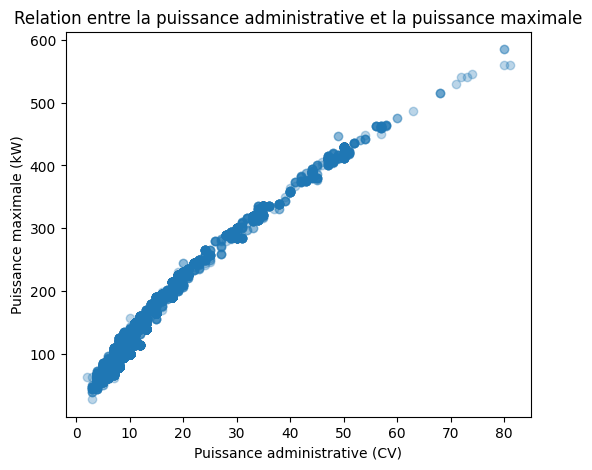

In [118]:
# Visualisation
plt.figure(figsize=(6, 5))
plt.scatter(
    X_train["puiss_admin_98"],
    X_train["puiss_max"],
    alpha=0.3
)

plt.xlabel("Puissance administrative (CV)")
plt.ylabel("Puissance maximale (kW)")
plt.title("Relation entre la puissance administrative et la puissance maximale")

plt.show()

### Analyse des résultats et décision retenue

La matrice de corrélation met en évidence une corrélation très élevée (**0,973**) entre `puiss_admin_98` et `puiss_max`.

Le nuage de points confirme cette relation positive très forte : les deux variables évoluent de manière similaire et présentent une importante redondance.

Afin de limiter cette redondance et de simplifier le jeu de données, seule la variable `puiss_max`, correspondant à la puissance maximale réelle du moteur, est retenue pour la modélisation.

La variable `puiss_admin_98` sera donc supprimée des jeux d'entraînement et de test.

In [119]:
# Suppression de la variable redondante puiss_admin_98
X_train = X_train.drop(columns=["puiss_admin_98"])
X_test = X_test.drop(columns=["puiss_admin_98"])

# Vérification
print("Dimensions de X_train :", X_train.shape)
print("Dimensions de X_test :", X_test.shape)

print("Variable présente dans X_train :", "puiss_admin_98" in X_train.columns)
print("Variable présente dans X_test :", "puiss_admin_98" in X_test.columns)

Dimensions de X_train : (44002, 23)
Dimensions de X_test : (11001, 23)
Variable présente dans X_train : False
Variable présente dans X_test : False


## Variables de consommation

Le jeu de données contient trois variables décrivant la consommation de carburant dans différents contextes de conduite :

- `conso_urb` : consommation en cycle urbain ;
- `conso_exurb` : consommation en cycle extra-urbain ;
- `conso_mixte` : consommation en cycle mixte.

Une analyse de corrélation a été réalisée afin d'évaluer le niveau de redondance entre ces trois variables.

In [120]:
# Matrice de corrélation
X_train[
    ["conso_urb", "conso_exurb", "conso_mixte"]
].corr()

,conso_urb,conso_exurb,conso_mixte
conso_urb,1.000000,0.860074,0.969379
conso_exurb,0.860074,1.000000,0.954900
conso_mixte,0.969379,0.954900,1.000000


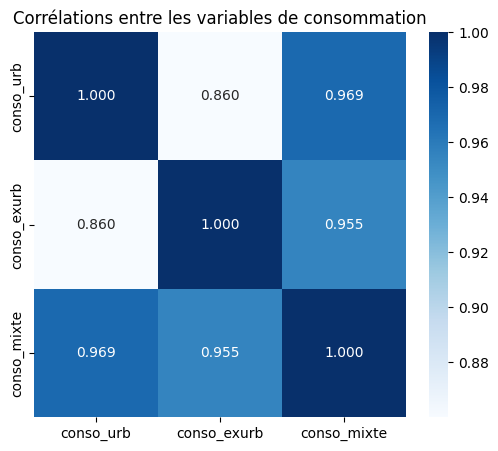

In [121]:
# Heatmap
plt.figure(figsize=(6,5))

sns.heatmap(
    X_train[
        ["conso_urb", "conso_exurb", "conso_mixte"]
    ].corr(),
    annot=True,
    cmap="Blues",
    fmt=".3f"
)

plt.title("Corrélations entre les variables de consommation")
plt.show()

### Analyse des résultats et décision retenue

La matrice de corrélation et la heatmap mettent en évidence de fortes corrélations positives entre les trois variables de consommation.

La variable `conso_mixte` présente une corrélation de **0,969** avec `conso_urb` et de **0,955** avec `conso_exurb`. La corrélation entre `conso_urb` et `conso_exurb` atteint **0,860**.

Ces résultats montrent une importante redondance entre les trois variables.

Afin de simplifier le jeu de données et de limiter cette redondance, seule la variable `conso_mixte`, représentative de la consommation globale du véhicule, est retenue pour cette première approche de modélisation.

Les variables `conso_urb` et `conso_exurb` seront donc supprimées des jeux d'entraînement et de test.

Cette décision pourra être réévaluée lors de la modélisation afin de vérifier si leur conservation améliore les performances prédictives.

## Variables de masse

## Variables `masse_ordma_min` et `masse_ordma_max`

Les variables `masse_ordma_min` et `masse_ordma_max` représentent respectivement la masse minimale et la masse maximale homologuées du véhicule.

Une analyse de corrélation a été réalisée afin d'évaluer le niveau de redondance entre ces deux variables avant d'envisager une éventuelle suppression.

In [122]:
# Corrélation
X_train[["masse_ordma_min", "masse_ordma_max"]].corr()

,masse_ordma_min,masse_ordma_max
masse_ordma_min,1.000000,0.792372
masse_ordma_max,0.792372,1.000000


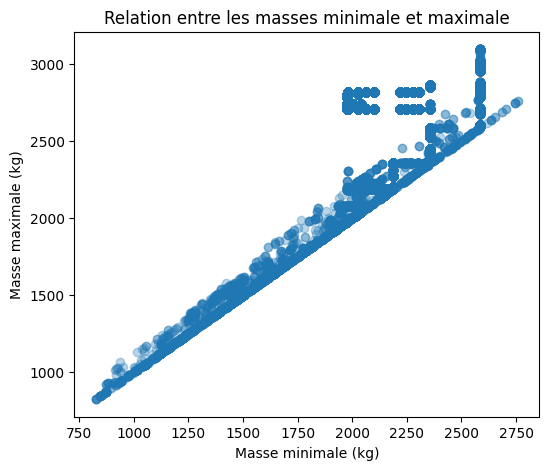

In [123]:
# Nuage de points
plt.figure(figsize=(6,5))

plt.scatter(
    X_train["masse_ordma_min"],
    X_train["masse_ordma_max"],
    alpha=0.3
)

plt.xlabel("Masse minimale (kg)")
plt.ylabel("Masse maximale (kg)")
plt.title("Relation entre les masses minimale et maximale")

plt.show()

### Analyse des résultats et décision retenue

La matrice de corrélation met en évidence une corrélation positive élevée (**0,792**) entre `masse_ordma_min` et `masse_ordma_max`.

Le nuage de points confirme cette relation, tout en montrant une certaine dispersion, notamment pour les véhicules présentant des masses importantes.

Cette corrélation reste inférieure à celles observées entre les variables de puissance et de consommation. Les deux variables peuvent donc apporter des informations complémentaires pour la prédiction des émissions de CO₂.

**Décision retenue :** les variables `masse_ordma_min` et `masse_ordma_max` sont conservées pour la modélisation.

## Analyse des ratios puissance/masse

Deux variables ont été créées lors du Feature Engineering :

- `rapport_puissance_masse` : rapport entre la puissance maximale du moteur et la masse minimale du véhicule.
- `rapport_puissance_masse_max` : rapport entre la puissance maximale du moteur et la masse maximale du véhicule.

Ces deux variables reposent sur des caractéristiques techniques proches et pourraient présenter une certaine redondance.

Une analyse de corrélation est réalisée sur le jeu d'entraînement afin d'évaluer leur relation et leur association avec les émissions de CO₂.

L'objectif est de déterminer s'il est pertinent de conserver les deux ratios pour la modélisation.

In [124]:

# ==================================================
# ANALYSE DES RATIOS PUISSANCE/MASSE
# ==================================================

variables_ratios = [
    "rapport_puissance_masse",
    "rapport_puissance_masse_max"
]

# Corrélation entre les deux ratios
print("Corrélation entre les deux ratios :")
print(X_train[variables_ratios].corr())

# Corrélation avec la variable cible CO2
print("\nCorrélation avec les émissions de CO2 :")

for variable in variables_ratios:
    correlation = X_train[variable].corr(y_train)
    print(f"{variable} : {correlation:.4f}")


Corrélation entre les deux ratios :
                             rapport_puissance_masse  \
rapport_puissance_masse                     1.000000   
rapport_puissance_masse_max                 0.984769   

                             rapport_puissance_masse_max  
rapport_puissance_masse                         0.984769  
rapport_puissance_masse_max                     1.000000  

Corrélation avec les émissions de CO2 :
rapport_puissance_masse : 0.0818
rapport_puissance_masse_max : 0.0472


### Analyse des résultats et décision retenue

L'analyse des corrélations met en évidence une **très forte corrélation entre les deux ratios puissance/masse (0,9848)**, ce qui suggère une importante redondance entre ces variables.

Leur corrélation avec les émissions de CO₂ reste faible :

- `rapport_puissance_masse` : **0,0818**.
- `rapport_puissance_masse_max` : **0,0472**.

Bien que ces corrélations ne permettent pas de conclure à l'absence de relations non linéaires avec la variable cible, les deux ratios semblent apporter des informations proches.

**Décision retenue :** conserver `rapport_puissance_masse` et supprimer `rapport_puissance_masse_max` afin de limiter la redondance entre les variables explicatives.

L'intérêt de cette sélection pourra être réévalué lors de la comparaison des performances des modèles.

## Synthèse de la sélection des variables numériques

L'analyse des variables numériques a permis d'identifier plusieurs variables présentant une forte redondance.

Les décisions suivantes ont été retenues :

- `puiss_admin_98` : supprimée en raison de sa très forte corrélation avec `puiss_max` (0,973).
- `conso_urb` et `conso_exurb` : suppression retenue en raison de leur forte corrélation avec `conso_mixte` (respectivement 0,969 et 0,955).
- `puiss_max` et `conso_mixte` : conservées pour la modélisation.
- `masse_ordma_min` et `masse_ordma_max` : conservées car elles peuvent apporter des informations complémentaires.
- `rapport_puissance_masse` et `rapport_puissance_masse_max` : très fortement corrélées entre elles (0,9848). Leurs corrélations respectives avec les émissions de CO₂ sont faibles (0,0818 et 0,0472). Afin de limiter la redondance, **`rapport_puissance_masse` est conservée et `rapport_puissance_masse_max` est supprimée**.


Ces choix visent à simplifier le jeu de données tout en préservant les informations potentiellement pertinentes pour la prédiction des émissions de CO₂. L'intérêt de cette sélection pourra être réévalué lors de la modélisation.

In [125]:
# ==================================================
# SUPPRESSION DES VARIABLES DE CONSOMMATION REDONDANTES
# ==================================================

colonnes_a_supprimer = ["conso_urb", "conso_exurb"]

X_train = X_train.drop(columns=colonnes_a_supprimer)
X_test = X_test.drop(columns=colonnes_a_supprimer)

# Vérification
print("Dimensions de X_train :", X_train.shape)
print("Dimensions de X_test :", X_test.shape)

print("\nVariables encore présentes dans X_train :")
print([col for col in colonnes_a_supprimer if col in X_train.columns])

print("\nVariables encore présentes dans X_test :")
print([col for col in colonnes_a_supprimer if col in X_test.columns])

Dimensions de X_train : (44002, 21)
Dimensions de X_test : (11001, 21)

Variables encore présentes dans X_train :
[]

Variables encore présentes dans X_test :
[]


## Sélection des variables textuelles

Les variables textuelles présentant un grand nombre de modalités ont fait l'objet d'une analyse spécifique afin d'évaluer leur intérêt pour la modélisation. Pour chacune d'elles, le nombre de modalités, leur fréquence et leur caractère potentiellement redondant ont été étudiés afin de déterminer si leur conservation était pertinente.

In [126]:
# Analyse de la variable cnit
print("Nombre de modalités :", X_train["cnit"].nunique())
print()

X_train["cnit"].value_counts().head(10)

Nombre de modalités : 43965



cnit
M10FATVP024A496    2
M10LADVP0005040    2
M10FATVP001E559    2
M10FATVP008N683    2
M10PELVP253J535    2
M10PELVP256R480    2
M10FATVP004M528    2
M10PELVP253J536    2
M10FATVP022D343    2
M10DACVP0008731    2
Name: count, dtype: int64

### Analyse des résultats et décision retenue

La variable `cnit` présente **43 965 modalités distinctes** pour **44 002 observations** dans le jeu d'entraînement.

Cette cardinalité extrêmement élevée montre qu'elle se comporte quasiment comme un identifiant technique unique.

Son encodage, notamment par One-Hot Encoding, entraînerait une augmentation considérable du nombre de variables, avec un risque de surapprentissage et une capacité de généralisation limitée.

**Décision retenue :** la variable `cnit` ne sera pas conservée pour cette première approche de modélisation.

In [127]:
# Analyse de la variable tvv
print("Nombre de modalités :", X_train["tvv"].nunique())
print()

X_train["tvv"].value_counts().head(10)

Nombre de modalités : 30735



tvv
639/2LAA71305N3M3F2W27    4
639/2LAA71280N2M3G2T28    4
639/2LAA31280N2M3F2U38    4
639/2KAA31305N1M3G2S39    4
639/2KAA71305N1M3F2T29    4
639/2KAA31280N1M3D2U29    4
639/2KAA31305N1M3F2V29    4
639/2LAA31305N2M3F2U37    4
639/2KAA31280N1M3F2T39    4
639/2KAA31305N3M3C2T39    4
Name: count, dtype: int64

### Analyse des résultats et décision retenue

La variable `tvv` présente **30 735 modalités distinctes** pour **44 002 observations** dans le jeu d'entraînement.

Cette forte cardinalité montre qu'elle correspond à des références techniques très spécifiques, dont les modalités apparaissent peu fréquemment.

Son encodage, notamment par One-Hot Encoding, entraînerait une augmentation importante du nombre de variables, avec un risque de surapprentissage et sans garantie d'amélioration des performances prédictives.

**Décision retenue :** la variable `tvv` ne sera pas conservée pour cette première approche de modélisation.

In [128]:
# Analyse de la variable dscom
print("Nombre de modalités :", X_train["dscom"].nunique())
print()

X_train["dscom"].value_counts().head(10)

Nombre de modalités : 3250



dscom
VIANO 2.2 CDI                  4725
VIANO 2.0 CDI                  3139
COMBI 116 CDI                  2970
COMBI 113 CDI                  2082
VIANO 3.0 CDI                  1292
SPRINTER COMBI 213 CDI - 32    1235
SPRINTER COMBI 213 CDI - 43    1018
SPRINTER COMBI 213 CDI - 37     884
SPRINTER COMBI 316 CDI - 37     866
VIANO 2.2 CDI 4x4               768
Name: count, dtype: int64

### Analyse des résultats et décision retenue

La variable `dscom` présente **3 250 modalités distinctes** dans le jeu d'entraînement, correspondant aux désignations commerciales des véhicules.

Certaines modalités sont fortement représentées, notamment `VIANO 2.2 CDI` (4 725 observations) et `VIANO 2.0 CDI` (3 139 observations).

Cette variable contient des informations relatives aux modèles et aux motorisations, potentiellement utiles pour prédire les émissions de CO₂. Toutefois, une partie de ces informations peut être redondante avec d'autres caractéristiques du jeu de données.

Son encodage, notamment par One-Hot Encoding, pourrait augmenter considérablement le nombre de variables et la complexité du modèle.

**Décision retenue :** la variable `dscom` ne sera pas conservée pour cette première approche de modélisation. Son intérêt prédictif pourra être réévalué ultérieurement à l'aide de méthodes d'encodage adaptées, comme le Target Encoding.

In [129]:
# Analyse de la variable lib_mod
print("Nombre de modalités :", X_train["lib_mod"].nunique())
print()

X_train["lib_mod"].value_counts().head(10)

Nombre de modalités : 423



lib_mod
VIANO        11288
CRAFTER      10616
VITO          7833
SPRINTER      6541
E 200          370
C 180          222
C 200          203
E 220          201
E 250          175
PRIMASTAR      135
Name: count, dtype: int64

### Analyse des résultats et décision retenue

La variable `lib_mod` présente **423 modalités distinctes** dans le jeu d'entraînement, correspondant aux modèles commerciaux des véhicules.

Les modèles les plus représentés sont `VIANO` (11 288 observations), `CRAFTER` (10 616), `VITO` (7 833) et `SPRINTER` (6 541).

Cette variable peut apporter une information complémentaire à la marque (`lib_mrq`), mais son nombre élevé de modalités rend son encodage potentiellement coûteux en termes de dimensionnalité.

**Décision retenue :** la variable `lib_mod` ne sera pas conservée dans cette première approche de modélisation afin de limiter la complexité du jeu de données.

Son intérêt prédictif pourra être réévalué ultérieurement, notamment à l'aide du Target Encoding.

In [130]:
# Analyse de la variable lib_mod_doss
print("Nombre de modalités :", X_train["lib_mod_doss"].nunique())
print()

X_train["lib_mod_doss"].value_counts().head(10)

Nombre de modalités : 457



lib_mod_doss
VIANO         11288
CRAFTER       10616
VITO           7833
SPRINTER       6541
CLASSE E       1063
CLASSE C        738
CLASSE S        330
CLASSE CLS      151
CLASSE B        147
CLASSE A        147
Name: count, dtype: int64

### Analyse des résultats et décision retenue

La variable `lib_mod_doss` présente **457 modalités distinctes** dans le jeu d'entraînement, correspondant aux désignations des modèles de véhicules.

Les modèles les plus représentés sont `VIANO` (11 288 observations), `CRAFTER` (10 616), `VITO` (7 833) et `SPRINTER` (6 541).

Ces modalités présentent les mêmes effectifs que dans la variable `lib_mod`, ce qui suggère une forte proximité entre les deux variables et une possible redondance des informations.

Son encodage pourrait augmenter considérablement le nombre de variables explicatives sans garantir une amélioration des performances prédictives.

**Décision retenue :** la variable `lib_mod_doss` ne sera pas conservée dans cette première approche de modélisation afin de limiter la complexité du jeu de données.

Son intérêt prédictif pourra être réévalué ultérieurement, notamment à l'aide de méthodes d'encodage adaptées comme le Target Encoding.

## Synthèse de la sélection des variables textuelles

L'analyse des principales variables textuelles a permis d'identifier celles présentant un réel intérêt pour la modélisation.

Les variables `cnit`, `tvv`, `dscom`, `lib_mod` et `lib_mod_doss` ont été écartées en raison de leur très forte cardinalité, de leur nature technique ou de leur redondance avec d'autres variables explicatives.

À l'inverse, la variable `lib_mrq`, dont la cardinalité reste raisonnable et qui présente un intérêt métier, est conservée pour l'encodage.

## Application des décisions de sélection des variables

Les analyses précédentes ont permis d'identifier les variables à conserver ainsi que celles à écarter. Les décisions retenues sont désormais appliquées aux jeux d'entraînement et de test afin d'obtenir un ensemble de variables cohérent avant l'encodage des variables catégorielles.

Cette étape permet de réduire la redondance entre les variables explicatives et de simplifier le jeu de données tout en conservant les informations les plus pertinentes pour la modélisation.

In [131]:
# ==================================================
# APPLICATION DES DÉCISIONS DE SÉLECTION DES VARIABLES
# ==================================================

variables_a_supprimer = [
    "champ_v9",
    "puiss_admin_98",
    "rapport_puissance_masse_max",
    "conso_urb",
    "conso_exurb",
    "cnit",
    "tvv",
    "dscom",
    "lib_mod",
    "lib_mod_doss"
]

# Suppression dans les deux jeux de données
# errors="ignore" évite une erreur si une variable
# a déjà été supprimée précédemment.

X_train = X_train.drop(
    columns=variables_a_supprimer,
    errors="ignore"
)

X_test = X_test.drop(
    columns=variables_a_supprimer,
    errors="ignore"
)

# Vérification des dimensions
print("Dimensions de X_train :", X_train.shape)
print("Dimensions de X_test :", X_test.shape)

# Vérification des variables restantes à supprimer
print(
    "Variables encore présentes dans X_train :",
    [col for col in variables_a_supprimer if col in X_train.columns]
)

print(
    "Variables encore présentes dans X_test :",
    [col for col in variables_a_supprimer if col in X_test.columns]
)


Dimensions de X_train : (44002, 14)
Dimensions de X_test : (11001, 14)
Variables encore présentes dans X_train : []
Variables encore présentes dans X_test : []


Conformément aux décisions prises lors de la sélection des variables, les variables numériques et textuelles jugées peu pertinentes ou redondantes ont été supprimées des jeux d'entraînement et de test.

Les jeux de données obtenus sont désormais constitués uniquement des variables retenues pour la modélisation. Ils seront utilisés dans l'étape suivante pour l'encodage des variables catégorielles.

## Vérification de l'absence de valeurs manquantes

In [132]:
# ==================================================
# VÉRIFICATION FINALE DES VALEURS MANQUANTES
# ==================================================

print("Valeurs manquantes dans X_train :")
print(X_train.isna().sum().sum())

print("\nValeurs manquantes dans X_test :")
print(X_test.isna().sum().sum())

Valeurs manquantes dans X_train :
0

Valeurs manquantes dans X_test :
0


L'imputation des valeurs manquantes a été réalisée avec succès sur les jeux d'entraînement et de test. Une vérification après la sélection des variables confirme qu'aucune valeur manquante ne subsiste dans les données destinées à la modélisation.

Les statistiques d'imputation ont été calculées exclusivement sur le jeu d'entraînement puis appliquées au jeu de test, conformément aux bonnes pratiques de prétraitement, afin d'éviter tout risque de data leakage.

# Encodage des variables catégorielles

Les variables catégorielles retenues pour l'encodage ont été sélectionnées à l'issue de l'étape de sélection des variables, en fonction de leur intérêt pour la modélisation et de leur nombre de modalités.

Les variables `cnit`, `tvv`, `dscom`, `lib_mod` et `lib_mod_doss` n'ont pas été retenues en raison de leur très forte cardinalité, de leur nature technique ou de leur redondance avec d'autres variables explicatives.

À l'inverse, les variables `lib_mrq`, `cod_cbr`, `hybride`, `Carrosserie`, `gamme` et `typ_boite_nb_rapp` sont conservées et seront encodées à l'aide d'un encodage One-Hot avant la modélisation.

Conformément aux bonnes pratiques en Machine Learning, l'encodeur est ajusté uniquement sur le jeu d'entraînement (`X_train`), puis appliqué au jeu de test (`X_test`) afin d'éviter tout risque de data leakage.

In [133]:
# ==================================================
# VÉRIFICATION DES VARIABLES AVANT ENCODAGE
# ==================================================

print("Types des variables :")
print(X_train.dtypes)

print("\nNombre de modalités des variables catégorielles :")

variables_a_encoder = [
    "lib_mrq",
    "cod_cbr",
    "hybride",
    "Carrosserie",
    "gamme",
    "typ_boite_nb_rapp"
]

for col in variables_a_encoder:
    print(f"{col} : {X_train[col].nunique()} modalités")


Types des variables :
lib_mrq                     object
cod_cbr                     object
hybride                     object
puiss_max                  float64
typ_boite_nb_rapp           object
conso_mixte                float64
co_typ_1                   float64
nox                        float64
ptcl                       float64
masse_ordma_min              int64
masse_ordma_max              int64
Carrosserie                 object
gamme                       object
rapport_puissance_masse    float64
dtype: object

Nombre de modalités des variables catégorielles :
lib_mrq : 44 modalités
cod_cbr : 12 modalités
hybride : 2 modalités
Carrosserie : 11 modalités
gamme : 7 modalités
typ_boite_nb_rapp : 15 modalités


In [134]:

# ==================================================
# ANALYSE DE LA VARIABLE TYP_BOITE_NB_RAPP
# ==================================================

print("Répartition des modalités :")
print(X_train["typ_boite_nb_rapp"].value_counts(dropna=False))

Répartition des modalités :
typ_boite_nb_rapp
M 6    25444
A 5    10883
A 7     5385
M 5      800
A 6      663
A 8      425
V 0      245
D 5       50
A 9       26
D 6       23
A 4       20
D 7       20
M 7       15
V .        2
S 6        1
Name: count, dtype: int64



### Analyse de la variable `typ_boite_nb_rapp`

La variable `typ_boite_nb_rapp` présente **15 modalités distinctes** dans le jeu d'entraînement.

Elle combine des informations relatives au type de boîte de vitesses et au nombre de rapports. Les modalités les plus représentées sont `M 6` (25 444 observations), `A 5` (10 883) et `A 7` (5 385).

Cette variable présente un intérêt potentiel pour la prédiction des émissions de CO₂, car les caractéristiques de transmission peuvent influencer la consommation de carburant.

**Décision retenue :** la variable est conservée et sera encodée par One-Hot Encoding, comme les autres variables catégorielles.

Une décomposition en deux variables distinctes (type de boîte et nombre de rapports) pourra être envisagée comme piste d'amélioration.

In [135]:
from sklearn.preprocessing import OneHotEncoder

variables_a_encoder = [
    "lib_mrq",
    "cod_cbr",
    "hybride",
    "Carrosserie",
    "gamme",
    "typ_boite_nb_rapp"
]

encoder = OneHotEncoder(
    drop="first",
    handle_unknown="ignore",
    sparse_output=False
)

In [136]:
# Ajustement de l'encodeur sur le jeu d'entraînement
encoder.fit(X_train[variables_a_encoder])

,categories,'auto'
,drop,'first'
,sparse_output,False
,dtype,<class 'numpy.float64'>
,handle_unknown,'ignore'
,min_frequency,None
,max_categories,None
,feature_name_combiner,'concat'


In [137]:
# Transformation des variables catégorielles
# Certaines catégories très rares peuvent être présentes uniquement dans le jeu de test.
# Elles sont automatiquement ignorées grâce au paramètre handle_unknown="ignore".

with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message="Found unknown categories"
    )

    X_train_encoded = encoder.transform(X_train[variables_a_encoder])
    X_test_encoded = encoder.transform(X_test[variables_a_encoder])

In [138]:
# Récupération des noms des variables créées
colonnes_encodees = encoder.get_feature_names_out(variables_a_encoder)

print(f"Nombre de variables créées : {len(colonnes_encodees)}")
print(colonnes_encodees)

Nombre de variables créées : 85
['lib_mrq_ASTON MARTIN' 'lib_mrq_AUDI' 'lib_mrq_BENTLEY' 'lib_mrq_BMW'
 'lib_mrq_CADILLAC' 'lib_mrq_CHEVROLET' 'lib_mrq_CITROEN' 'lib_mrq_DACIA'
 'lib_mrq_FERRARI' 'lib_mrq_FIAT' 'lib_mrq_FORD' 'lib_mrq_HONDA'
 'lib_mrq_HYUNDAI' 'lib_mrq_INFINITI' 'lib_mrq_JAGUAR' 'lib_mrq_JEEP'
 'lib_mrq_KIA' 'lib_mrq_LADA' 'lib_mrq_LAMBORGHINI' 'lib_mrq_LANCIA'
 'lib_mrq_LAND ROVER' 'lib_mrq_LEXUS' 'lib_mrq_LOTUS' 'lib_mrq_MASERATI'
 'lib_mrq_MAZDA' 'lib_mrq_MERCEDES' 'lib_mrq_MINI' 'lib_mrq_MITSUBISHI'
 'lib_mrq_NISSAN' 'lib_mrq_OPEL' 'lib_mrq_PEUGEOT' 'lib_mrq_PORSCHE'
 'lib_mrq_RENAULT' 'lib_mrq_ROLLS-ROYCE' 'lib_mrq_SEAT' 'lib_mrq_SKODA'
 'lib_mrq_SMART' 'lib_mrq_SSANGYONG' 'lib_mrq_SUBARU' 'lib_mrq_SUZUKI'
 'lib_mrq_TOYOTA' 'lib_mrq_VOLKSWAGEN' 'lib_mrq_VOLVO' 'cod_cbr_EH'
 'cod_cbr_ES' 'cod_cbr_ES/GN' 'cod_cbr_ES/GP' 'cod_cbr_FE' 'cod_cbr_GH'
 'cod_cbr_GL' 'cod_cbr_GN' 'cod_cbr_GN/ES' 'cod_cbr_GO' 'cod_cbr_GP/ES'
 'hybride_oui' 'Carrosserie_BREAK' 'Carrosserie_CA

### Bilan de l'encodage des variables catégorielles

L'encodage des variables catégorielles a été réalisé à l'aide de `OneHotEncoder` de Scikit-learn.

Les six variables retenues (`lib_mrq`, `cod_cbr`, `hybride`, `Carrosserie`, `gamme` et `typ_boite_nb_rapp`) ont généré **85 variables indicatrices binaires**.

Le paramètre `drop="first"` a permis de supprimer une modalité de référence pour chacune des six variables catégorielles, afin de limiter le nombre de colonnes créées.

L'encodeur a été ajusté exclusivement sur le jeu d'entraînement (`X_train`), puis utilisé pour transformer les jeux d'entraînement et de test, afin d'éviter toute fuite d'information (*data leakage*).

Le paramètre `handle_unknown="ignore"` permet de gérer les catégories éventuellement présentes dans le jeu de test mais absentes du jeu d'entraînement.

Les variables présentant une très forte cardinalité (`cnit`, `tvv`, `dscom`, `lib_mod` et `lib_mod_doss`) ont été exclues lors de la sélection des variables afin de limiter la dimension du jeu de données.

L'encodage permet ainsi de rendre les variables catégorielles exploitables par les futurs modèles de Machine Learning.

## Reconstruction des jeux de données

In [139]:
# Conversion des variables encodées en DataFrame
X_train_encoded = pd.DataFrame(
    X_train_encoded,
    columns=colonnes_encodees,
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded,
    columns=colonnes_encodees,
    index=X_test.index
)

In [140]:
# Suppression des variables catégorielles d'origine
X_train_num = X_train.drop(columns=variables_a_encoder)

X_test_num = X_test.drop(columns=variables_a_encoder)

In [141]:
# Reconstruction des jeux de données finaux
X_train_final = pd.concat(
    [X_train_num, X_train_encoded],
    axis=1
)

X_test_final = pd.concat(
    [X_test_num, X_test_encoded],
    axis=1
)

### Vérification

In [142]:
print("Dimensions de X_train_final :", X_train_final.shape)
print("Dimensions de X_test_final  :", X_test_final.shape)

Dimensions de X_train_final : (44002, 93)
Dimensions de X_test_final  : (11001, 93)


In [143]:
X_train_final.head()

,puiss_max,conso_mixte,co_typ_1,nox,ptcl,masse_ordma_min,masse_ordma_max,rapport_puissance_masse,lib_mrq_ASTON MARTIN,lib_mrq_AUDI,lib_mrq_BENTLEY,lib_mrq_BMW,lib_mrq_CADILLAC,lib_mrq_CHEVROLET,lib_mrq_CITROEN,lib_mrq_DACIA,lib_mrq_FERRARI,lib_mrq_FIAT,lib_mrq_FORD,lib_mrq_HONDA,lib_mrq_HYUNDAI,lib_mrq_INFINITI,lib_mrq_JAGUAR,lib_mrq_JEEP,lib_mrq_KIA,lib_mrq_LADA,lib_mrq_LAMBORGHINI,lib_mrq_LANCIA,lib_mrq_LAND ROVER,lib_mrq_LEXUS,lib_mrq_LOTUS,lib_mrq_MASERATI,lib_mrq_MAZDA,lib_mrq_MERCEDES,lib_mrq_MINI,lib_mrq_MITSUBISHI,lib_mrq_NISSAN,lib_mrq_OPEL,lib_mrq_PEUGEOT,lib_mrq_PORSCHE,lib_mrq_RENAULT,lib_mrq_ROLLS-ROYCE,lib_mrq_SEAT,lib_mrq_SKODA,lib_mrq_SMART,lib_mrq_SSANGYONG,lib_mrq_SUBARU,lib_mrq_SUZUKI,lib_mrq_TOYOTA,lib_mrq_VOLKSWAGEN,lib_mrq_VOLVO,cod_cbr_EH,cod_cbr_ES,cod_cbr_ES/GN,cod_cbr_ES/GP,cod_cbr_FE,cod_cbr_GH,cod_cbr_GL,cod_cbr_GN,cod_cbr_GN/ES,cod_cbr_GO,cod_cbr_GP/ES,hybride_oui,Carrosserie_BREAK,Carrosserie_CABRIOLET,Carrosserie_COMBISPACE,Carrosserie_COMBISPCACE,Carrosserie_COUPE,Carrosserie_MINIBUS,Carrosserie_MINISPACE,Carrosserie_MONOSPACE,Carrosserie_MONOSPACE COMPACT,Carrosserie_TS TERRAINS/CHEMINS,gamme_INFERIEURE,gamme_LUXE,gamme_MOY-INFER,gamme_MOY-INFERIEURE,gamme_MOY-SUPER,gamme_SUPERIEURE,typ_boite_nb_rapp_A 5,typ_boite_nb_rapp_A 6,typ_boite_nb_rapp_A 7,typ_boite_nb_rapp_A 8,typ_boite_nb_rapp_A 9,typ_boite_nb_rapp_D 5,typ_boite_nb_rapp_D 6,typ_boite_nb_rapp_D 7,typ_boite_nb_rapp_M 5,typ_boite_nb_rapp_M 6,typ_boite_nb_rapp_M 7,typ_boite_nb_rapp_S 6,typ_boite_nb_rapp_V .,typ_boite_nb_rapp_V 0
24728,120.0,7.2,0.046,0.197,0.000,2076,2185,0.057803,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
65,125.0,5.2,0.440,0.030,0.001,1380,1380,0.090580,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
52499,120.0,7.4,0.401,0.213,0.001,2246,2709,0.053428,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
22245,120.0,7.7,0.175,0.226,0.001,2186,2355,0.054895,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
24305,120.0,7.7,0.046,0.197,0.000,2186,2350,0.054895,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [144]:

# ==================================================
# CONTRÔLE FINAL DES JEUX DE DONNÉES
# ==================================================

print("Valeurs manquantes dans X_train_final :",
      X_train_final.isna().sum().sum())

print("Valeurs manquantes dans X_test_final :",
      X_test_final.isna().sum().sum())

print("\nTypes des variables :")
print(X_train_final.dtypes.value_counts())
print(X_test_final.dtypes.value_counts())

Valeurs manquantes dans X_train_final : 0
Valeurs manquantes dans X_test_final : 0

Types des variables :
float64    91
int64       2
Name: count, dtype: int64
float64    91
int64       2
Name: count, dtype: int64


### Bilan de la reconstruction des jeux de données

Après l'encodage One-Hot, les variables catégorielles d'origine ont été remplacées par les variables indicatrices correspondantes.

Les jeux de données finaux ont été reconstruits en réunissant les **8 variables numériques** et les **85 variables issues de l'encodage**.

Les dimensions obtenues sont les suivantes :

- **X_train_final :** 44 002 observations et 93 variables explicatives.
- **X_test_final :** 11 001 observations et 93 variables explicatives.

Les vérifications finales confirment que :

- Les deux jeux de données possèdent le même nombre de variables.
- Aucune valeur manquante n'est présente.
- Toutes les variables sont numériques : 91 variables de type `float64` et 2 de type `int64`.

La variable `rapport_puissance_masse_max` a été supprimée à l'issue de l'analyse de redondance, tandis que `rapport_puissance_masse` a été conservée.

Les jeux de données sont donc correctement reconstruits et peuvent être utilisés pour les prochaines étapes de préparation et de modélisation.

## Sauvegarde des jeux de données prétraités

À l'issue des différentes étapes de prétraitement, les jeux de données d'entraînement et de test sont sauvegardés au format CSV afin de préparer la phase de modélisation.

Cette séparation permet de conserver une organisation claire du projet en distinguant les étapes de prétraitement et de modélisation. Les fichiers générés serviront directement de point d'entrée pour le notebook de modélisation.

In [145]:
# Sauvegarde des jeux de données prétraités

X_train_final.to_csv("../data/X_train_final.csv", index=False)
X_test_final.to_csv("../data/X_test_final.csv", index=False)

y_train.to_frame(name="co2").to_csv("../data/y_train.csv", index=False)
y_test.to_frame(name="co2").to_csv("../data/y_test.csv", index=False)

print("Les jeux de données prétraités ont été sauvegardés avec succès.")

Les jeux de données prétraités ont été sauvegardés avec succès.


### Vérification

In [146]:
import os

fichiers = [
    "../data/X_train_final.csv",
    "../data/X_test_final.csv",
    "../data/y_train.csv",
    "../data/y_test.csv"
]

for fichier in fichiers:
    print(f"{os.path.basename(fichier)} : {'OK' if os.path.exists(fichier) else 'Non trouvé'}")

X_train_final.csv : OK
X_test_final.csv : OK
y_train.csv : OK
y_test.csv : OK


### Bilan de la sauvegarde des données prétraitées

À l'issue des étapes de prétraitement, les jeux de données ont été sauvegardés au format CSV dans le dossier `data`.

Quatre fichiers ont été générés :

- `X_train_final.csv` : variables explicatives du jeu d'entraînement (44 002 observations et 93 variables).
- `X_test_final.csv` : variables explicatives du jeu de test (11 001 observations et 93 variables).
- `y_train.csv` : variable cible `co2` du jeu d'entraînement.
- `y_test.csv` : variable cible `co2` du jeu de test.

Une vérification de l'existence des fichiers a été effectuée avec `os.path.exists()`. Les quatre fichiers ont été retrouvés avec succès.

Cette sauvegarde permet de séparer les étapes de prétraitement et de modélisation, tout en facilitant la réutilisation des données préparées dans un notebook dédié.

## Export des objets de preprocessing

Les objets nécessaires au prétraitement des nouvelles observations sont sauvegardés afin de reproduire dans l'application Streamlit les transformations appliquées aux données d'entraînement.

In [147]:
import joblib
from pathlib import Path

models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

preprocessing = {
    # Encodeur entraîné
    "encoder": encoder,

    # Listes Python
    "variables_a_encoder": list(variables_a_encoder),
    "variables_a_supprimer": list(variables_a_supprimer),

    # Valeurs numériques simples
    "conso_mixte_mediane": float(conso_mixte_mediane),
    "ptcl_mediane": float(ptcl_mediane),
    "nox_mediane_globale": float(nox_mediane_globale),
    "co_typ1_mediane_globale": float(co_typ1_mediane_globale),

    # Conversion des Series pandas en dictionnaires Python
    "nox_medianes": {
        str(k): float(v)
        for k, v in nox_medianes.items()
    },

    "co_typ1_medianes": {
        str(k): float(v)
        for k, v in co_typ1_medianes.items()
    },

    # Liste Python
    "colonnes_finales": [
        str(col) for col in X_train_final.columns
    ]
}

joblib.dump(
    preprocessing,
    models_dir / "preprocessing_co2.joblib"
)

print("Preprocessing sauvegardé :", models_dir / "preprocessing_co2.joblib")

Preprocessing sauvegardé : ../models/preprocessing_co2.joblib


In [148]:

# ============================================================
# TEST DE COHÉRENCE DU PREPROCESSING POUR STREAMLIT
# ============================================================

import joblib


# Chargement des objets de preprocessing sauvegardés
preprocessing_charge = joblib.load(
    "../models/preprocessing_co2.joblib"
)

# Première observation du jeu de test après préparation
# des variables et avant encodage
observation_brute = X_test.iloc[[0]].copy()

# Récupération des paramètres sauvegardés
encoder_streamlit = preprocessing_charge["encoder"]
variables_cat = preprocessing_charge["variables_a_encoder"]
colonnes_finales = preprocessing_charge["colonnes_finales"]

# Encodage des variables catégorielles
donnees_encodees = encoder_streamlit.transform(
    observation_brute[variables_cat]
)

noms_colonnes_encodees = encoder_streamlit.get_feature_names_out(
    variables_cat
)

df_encode = pd.DataFrame(
    donnees_encodees,
    columns=noms_colonnes_encodees
)

# Récupération des 8 variables numériques conservées
variables_numeriques = [
    "puiss_max",
    "conso_mixte",
    "co_typ_1",
    "nox",
    "ptcl",
    "masse_ordma_min",
    "masse_ordma_max",
    "rapport_puissance_masse"
]

df_numerique = observation_brute[
    variables_numeriques
].reset_index(drop=True)

# Reconstruction de l'observation
observation_streamlit = pd.concat(
    [df_numerique, df_encode],
    axis=1
)

# Respect de l'ordre des 93 colonnes finales
observation_streamlit = observation_streamlit.reindex(
    columns=colonnes_finales
)

# Observation correspondante du jeu de test final
observation_originale = (
    X_test_final.iloc[[0]]
    .reset_index(drop=True)
)

# Comparaison des deux observations
difference = np.abs(
    observation_streamlit.to_numpy(dtype=float)
    - observation_originale.to_numpy(dtype=float)
)

print("Nombre de variables :", observation_streamlit.shape[1])
print("Différence maximale :", difference.max())
print("Nombre de différences :", np.count_nonzero(difference))

if np.allclose(
    observation_streamlit.to_numpy(dtype=float),
    observation_originale.to_numpy(dtype=float),
    equal_nan=True
):
    print("\n✅ PREPROCESSING COHÉRENT AVEC LE JEU DE TEST FINAL")
else:
    print("\n❌ DIFFÉRENCE DÉTECTÉE")


Nombre de variables : 93
Différence maximale : 0.0
Nombre de différences : 0

✅ PREPROCESSING COHÉRENT AVEC LE JEU DE TEST FINAL


### Bilan du test de cohérence du prétraitement

Un test de cohérence a été réalisé afin de vérifier que les objets de prétraitement sauvegardés permettent de reconstruire une observation conforme au jeu de données utilisé pour la modélisation.

Pour cela, une observation du jeu de test déjà prétraitée a été transformée à l'aide de l'encodeur sauvegardé, puis les variables numériques et catégorielles ont été assemblées dans le même ordre que les données finales.

Les résultats obtenus sont les suivants :

- **Nombre de variables :** 93.
- **Différence maximale :** 0.0.
- **Nombre de différences :** 0.

Le test confirme une correspondance exacte entre l'observation reconstruite et celle présente dans `X_test_final`.

Cette vérification valide la cohérence de l'encodage et de la reconstruction des variables. Un test complémentaire sur une observation entièrement brute sera nécessaire pour valider l'ensemble du prétraitement dans l'application Streamlit.